# 02 — Tiles and augmentation

## Setup

In [22]:
import os, sys, pathlib, warnings
root = pathlib.Path.cwd()
if root.name == "notebooks":
    root = root.parent
    os.chdir(root)
sys.path.insert(0, str(root))

# Warnings print the full path of the file that raised them.
warnings.filterwarnings("ignore", module="tqdm")
warnings.filterwarnings("ignore", message=".*IProgress.*")

In [23]:
import yaml, random, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

cfg = yaml.safe_load(open("configs/default.yaml"))
data = cfg["data"]
train_dir = Path(data["raw_dir"]) / "data" / "train"
ts = data["tile_size"]

NAME = "austin6"
img = np.array(Image.open(train_dir / "images" / f"{NAME}.tif").convert("RGB"))
msk = np.array(Image.open(train_dir / "gt" / f"{NAME}.tif").convert("L")) > 0

## Cutting into tiles

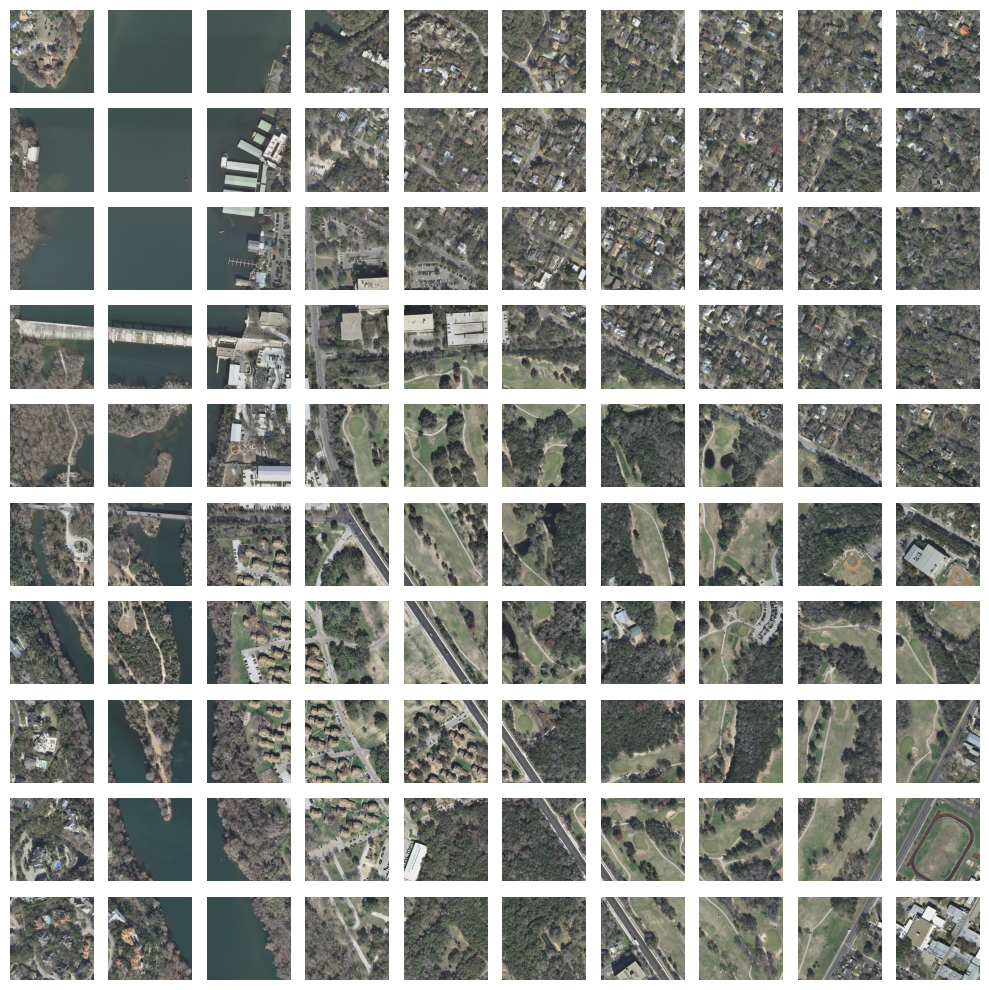

In [24]:
tiles, masks, coords = [], [], []
for top in range(0, 5000, ts):
    for left in range(0, 5000, ts):
        tiles.append(img[top:top + ts, left:left + ts])
        masks.append(msk[top:top + ts, left:left + ts])
        coords.append((top, left))

fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for ax, t in zip(axes.ravel(), tiles):
    ax.imshow(t); ax.axis("off")
plt.tight_layout(); plt.show()

## Empty tiles

32/100 tiles with no buildings


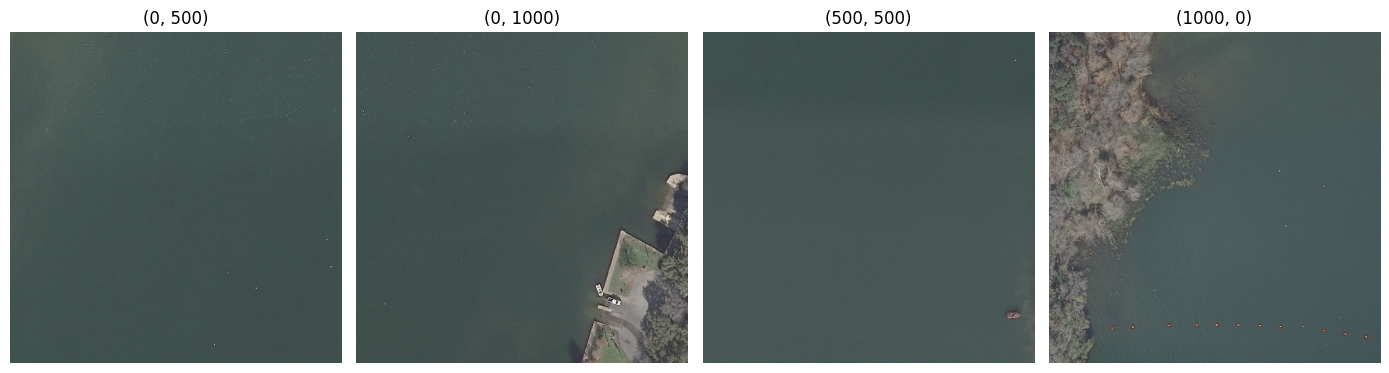

In [25]:
empty = [i for i, m in enumerate(masks) if not m.any()]
print(f"{len(empty)}/{len(masks)} tiles with no buildings")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(axes, empty[:4]):
    ax.imshow(tiles[i]); ax.set_title(str(coords[i])); ax.axis("off")
plt.tight_layout(); plt.show()

### keep_empty_fraction

In [26]:
rng = random.Random(cfg["seed"])
keep = data["keep_empty_fraction"]
kept = sum(1 for m in masks if m.any() or rng.random() < keep)

print("keep_empty_fraction:", keep, "(training only)")
print(f"train  {kept}/100 tiles from {NAME}")
print(f"val    100/100")
print(f"test   100/100")

keep_empty_fraction: 0.1 (training only)
train  75/100 tiles from austin6
val    100/100
test   100/100


## Augmentation

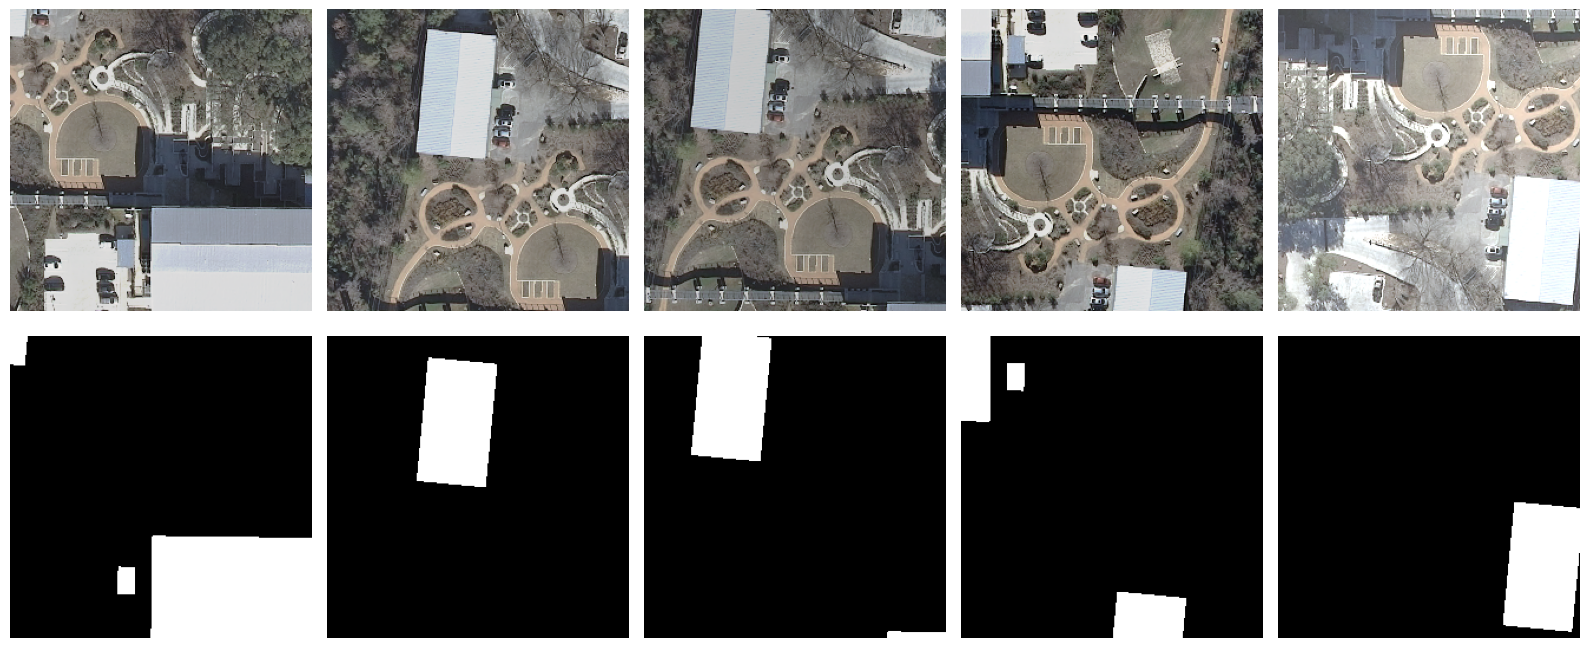

In [27]:
from src.dataset import train_transform

tf = train_transform(crop_size=cfg["train"]["crop_size"], seed=0)
tile, mask = tiles[42], masks[42].astype(np.uint8)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for col in range(5):
    out = tf(image=tile, mask=mask)
    shown = out["image"].permute(1, 2, 0).numpy() * 0.5 + 0.5
    axes[0, col].imshow(np.clip(shown, 0, 1)); axes[0, col].axis("off")
    axes[1, col].imshow(out["mask"], cmap="gray"); axes[1, col].axis("off")
plt.tight_layout(); plt.show()

## Normalization

In [28]:
from src.model import normalization_for

for arch in ("unet_scratch", "unet_resnet34", "deeplabv3plus_resnet34"):
    mean, std = normalization_for({"arch": arch})
    print(f"{arch:24} mean={tuple(round(m,3) for m in mean)}  std={tuple(round(s,3) for s in std)}")

x = np.array([0.0, 0.5, 1.0])
print("\nraw            ", x)
print("0.5/0.5        ", (x - 0.5) / 0.5)
print("ImageNet (red) ", ((x - 0.485) / 0.229).round(3))

unet_scratch             mean=(0.5, 0.5, 0.5)  std=(0.5, 0.5, 0.5)
unet_resnet34            mean=(0.485, 0.456, 0.406)  std=(0.229, 0.224, 0.225)
deeplabv3plus_resnet34   mean=(0.485, 0.456, 0.406)  std=(0.229, 0.224, 0.225)

raw             [0.  0.5 1. ]
0.5/0.5         [-1.  0.  1.]
ImageNet (red)  [-2.118  0.066  2.249]
